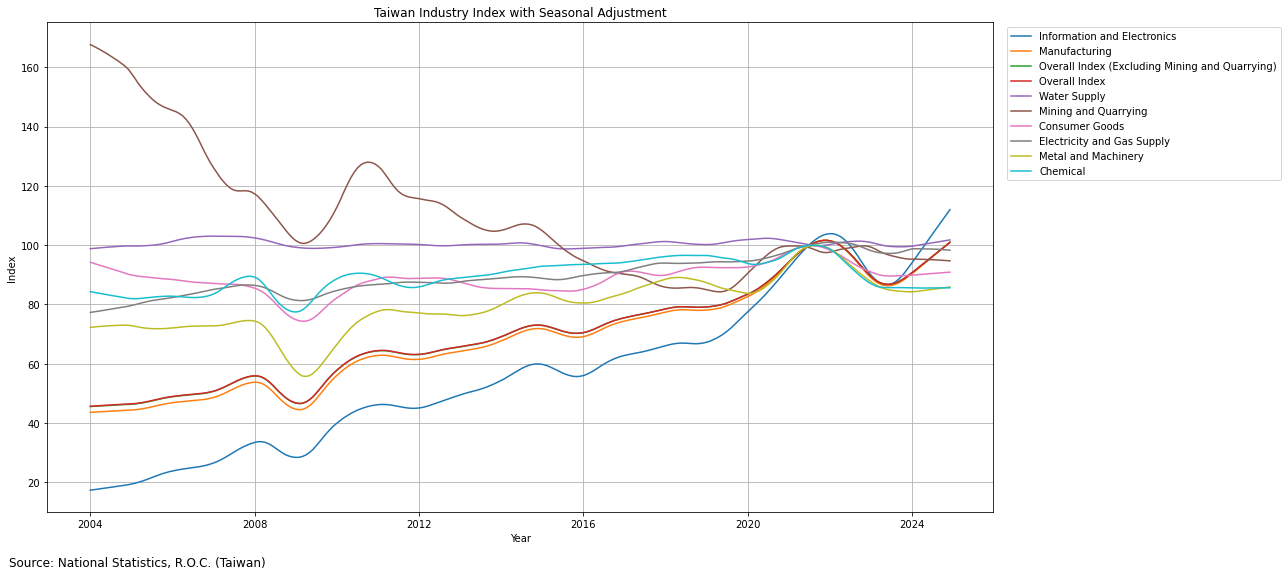

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
import matplotlib.dates as mdates

file_path = "industry index.xlsx"
df = pd.read_excel(file_path)
df.rename(columns={df.columns[0]: "Date"}, inplace=True)

df["Year"] = df["Date"].str.extract(r'(\d+)年')[0]
df["Month"] = df["Date"].str.extract(r'(\d+)月')[0]
df = df.dropna(subset=["Year", "Month"])
df["Year"] = df["Year"].astype(int) + 1911
df["Month"] = df["Month"].astype(int)
df["Date"] = pd.to_datetime(df[["Year", "Month"]].assign(day=1))
df.drop(columns=["Year", "Month"], inplace=True)

cols = ["Overall Index", "Overall Index (Excluding Mining and Quarrying)", "Mining and Quarrying",
        "Manufacturing", "Metal and Machinery", "Information and Electronics", "Chemical",
        "Consumer Goods", "Electricity and Gas Supply", "Water Supply"]

latest = df[df["Date"].dt.year == 2024].iloc[-1][cols]
sorted_cols = latest.sort_values(ascending=False).index.tolist()

plt.figure(figsize=(18, 8))
for col in sorted_cols:
    ts = pd.Series(df[col].values, index=df["Date"]).asfreq("MS")
    trend = STL(ts, period=12).fit().trend
    plt.plot(trend, label=col)

plt.title("Taiwan Industry Index with Seasonal Adjustment")
plt.xlabel("Year")
plt.ylabel("Index")
plt.grid(True)

plt.gca().xaxis.set_major_locator(mdates.YearLocator(base=4))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

handles, labels = plt.gca().get_legend_handles_labels()
ordered = [labels.index(label) for label in sorted_cols]
plt.legend([handles[idx] for idx in ordered],
           [labels[idx] for idx in ordered],
           loc="upper left", bbox_to_anchor=(1.01, 1.0))

plt.figtext(0.01, 0.01, "Source: National Statistics, R.O.C. (Taiwan)", ha='left', fontsize=12)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()